In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

sns.set_theme(style="whitegrid")

In [2]:
df = pd.read_csv("../data/raw/garment_productivity.csv")

print("Dataset shape:", df.shape)

df.head()

Dataset shape: (1197, 15)


,date,quarter,department,day,team,targeted_productivity,smv,wip,over_time,incentive,idle_time,idle_men,no_of_style_change,no_of_workers,actual_productivity
0,1/1/2015,Quarter1,sweing,Thursday,8,0.80,26.16,1108.0,7080,98,0.0,0,0,59.0,0.940725
1,1/1/2015,Quarter1,finishing,Thursday,1,0.75,3.94,NaN,960,0,0.0,0,0,8.0,0.886500
2,1/1/2015,Quarter1,sweing,Thursday,11,0.80,11.41,968.0,3660,50,0.0,0,0,30.5,0.800570
3,1/1/2015,Quarter1,sweing,Thursday,12,0.80,11.41,968.0,3660,50,0.0,0,0,30.5,0.800570
4,1/1/2015,Quarter1,sweing,Thursday,6,0.80,25.90,1170.0,1920,50,0.0,0,0,56.0,0.800382


In [3]:
df.info()
df.describe(include="all").T
print("Duplicate records:", df.duplicated().sum())
print("\nMissing values:")
print(df.isnull().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1197 entries, 0 to 1196
Data columns (total 15 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   date                   1197 non-null   object 
 1   quarter                1197 non-null   object 
 2   department             1197 non-null   object 
 3   day                    1197 non-null   object 
 4   team                   1197 non-null   int64  
 5   targeted_productivity  1197 non-null   float64
 6   smv                    1197 non-null   float64
 7   wip                    691 non-null    float64
 8   over_time              1197 non-null   int64  
 9   incentive              1197 non-null   int64  
 10  idle_time              1197 non-null   float64
 11  idle_men               1197 non-null   int64  
 12  no_of_style_change     1197 non-null   int64  
 13  no_of_workers          1197 non-null   float64
 14  actual_productivity    1197 non-null   float64
dtypes: f

In [4]:
numerical_columns = df.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_columns = df.select_dtypes(
    include=["object"]
).columns.tolist()

print("Numerical columns:")
print(numerical_columns)

print("\nCategorical columns:")
print(categorical_columns)

Numerical columns:
['team', 'targeted_productivity', 'smv', 'wip', 'over_time', 'incentive', 'idle_time', 'idle_men', 'no_of_style_change', 'no_of_workers', 'actual_productivity']

Categorical columns:
['date', 'quarter', 'department', 'day']


In [5]:
# Convert date column to datetime format
df["date"] = pd.to_datetime(df["date"], format="%m/%d/%Y")

# Verify conversion
print("Date data type:", df["date"].dtype)
print("Date range:", df["date"].min(), "to", df["date"].max())

Date data type: datetime64[ns]
Date range: 2015-01-01 00:00:00 to 2015-03-11 00:00:00


In [6]:
# Extract date-related features
df["month"] = df["date"].dt.month
df["day_of_month"] = df["date"].dt.day

# Remove original date column
df.drop(columns=["date"], inplace=True)

df.head()

,quarter,department,day,team,targeted_productivity,smv,wip,over_time,incentive,idle_time,idle_men,no_of_style_change,no_of_workers,actual_productivity,month,day_of_month
0,Quarter1,sweing,Thursday,8,0.80,26.16,1108.0,7080,98,0.0,0,0,59.0,0.940725,1,1
1,Quarter1,finishing,Thursday,1,0.75,3.94,NaN,960,0,0.0,0,0,8.0,0.886500,1,1
2,Quarter1,sweing,Thursday,11,0.80,11.41,968.0,3660,50,0.0,0,0,30.5,0.800570,1,1
3,Quarter1,sweing,Thursday,12,0.80,11.41,968.0,3660,50,0.0,0,0,30.5,0.800570,1,1
4,Quarter1,sweing,Thursday,6,0.80,25.90,1170.0,1920,50,0.0,0,0,56.0,0.800382,1,1


In [7]:
print("Updated shape:", df.shape)

print("\nMissing values:")
print(df.isnull().sum())

print("\nData types:")
print(df.dtypes)

Updated shape: (1197, 16)

Missing values:
quarter                    0
department                 0
day                        0
team                       0
targeted_productivity      0
smv                        0
wip                      506
over_time                  0
incentive                  0
idle_time                  0
idle_men                   0
no_of_style_change         0
no_of_workers              0
actual_productivity        0
month                      0
day_of_month               0
dtype: int64

Data types:
quarter                   object
department                object
day                       object
team                       int64
targeted_productivity    float64
smv                      float64
wip                      float64
over_time                  int64
incentive                  int64
idle_time                float64
idle_men                   int64
no_of_style_change         int64
no_of_workers            float64
actual_productivity      float64
month

In [8]:
# Define target variable
target = "actual_productivity"

# Exclude target and WIP from the input features
X = df.drop(columns=["actual_productivity", "wip"])
y = df[target]

# Treat team as categorical
X["team"] = X["team"].astype(str)

print("Input features shape:", X.shape)
print("Target shape:", y.shape)

print("\nTarget variable:")
print(y.head())

Input features shape: (1197, 14)
Target shape: (1197,)

Target variable:
0    0.940725
1    0.886500
2    0.800570
3    0.800570
4    0.800382
Name: actual_productivity, dtype: float64


In [9]:
# Identify feature types
numerical_features = X.select_dtypes(
    include=["int32", "int64", "float64"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object"]
).columns.tolist()

print("Numerical features:")
print(numerical_features)

print("\nCategorical features:")
print(categorical_features)

Numerical features:
['targeted_productivity', 'smv', 'over_time', 'incentive', 'idle_time', 'idle_men', 'no_of_style_change', 'no_of_workers', 'month', 'day_of_month']

Categorical features:
['quarter', 'department', 'day', 'team']


In [10]:
print("Missing values in X:", X.isnull().sum().sum())
print("Missing values in y:", y.isnull().sum())

Missing values in X: 0
Missing values in y: 0


In [11]:
# Reload dates from the original dataset
dates = pd.to_datetime(
    pd.read_csv("../data/raw/garment_productivity.csv")["date"],
    format="%m/%d/%Y"
)

# Find the chronological cutoff
unique_dates = sorted(dates.unique())
split_index = int(len(unique_dates) * 0.8)
cutoff_date = unique_dates[split_index]

# Create chronological train-test masks
train_mask = dates < cutoff_date
test_mask = dates >= cutoff_date

X_train = X.loc[train_mask].copy()
X_test = X.loc[test_mask].copy()

y_train = y.loc[train_mask].copy()
y_test = y.loc[test_mask].copy()

print("Cutoff date:", cutoff_date)
print("Training records:", len(X_train))
print("Testing records:", len(X_test))

print("\nTraining date range:")
print(dates[train_mask].min(), "to", dates[train_mask].max())

print("\nTesting date range:")
print(dates[test_mask].min(), "to", dates[test_mask].max())

Cutoff date: 2015-02-26 00:00:00
Training records: 943
Testing records: 254

Training date range:
2015-01-01 00:00:00 to 2015-02-25 00:00:00

Testing date range:
2015-02-26 00:00:00 to 2015-03-11 00:00:00


In [12]:
print("Training percentage:", round(len(X_train) / len(X) * 100, 2), "%")
print("Testing percentage:", round(len(X_test) / len(X) * 100, 2), "%")

print("\nTraining target mean:", y_train.mean())
print("Testing target mean:", y_test.mean())

Training percentage: 78.78 %
Testing percentage: 21.22 %

Training target mean: 0.7428822260540828
Testing target mean: 0.7061657634448819


In [13]:
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer

numerical_transformer = StandardScaler()

categorical_transformer = OneHotEncoder(
    drop="first",
    handle_unknown="ignore"
)

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numerical_transformer, numerical_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print("Preprocessing transformer created successfully!")

Preprocessing transformer created successfully!


In [14]:
# Fit on training data
X_train_processed = preprocessor.fit_transform(X_train)

# Transform testing data
X_test_processed = preprocessor.transform(X_test)

print("Training shape:", X_train_processed.shape)
print("Testing shape:", X_test_processed.shape)

Training shape: (943, 31)
Testing shape: (254, 31)


In [15]:
print("Training data contains missing values:",
      np.isnan(X_train_processed).sum())

print("Testing data contains missing values:",
      np.isnan(X_test_processed).sum())

Training data contains missing values: 0
Testing data contains missing values: 0


In [16]:
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

# Initialize models
models = {
    "Linear Regression": LinearRegression(),

    "Ridge Regression": Ridge(alpha=1.0),


    "Random Forest": RandomForestRegressor(
        n_estimators=200,
        random_state=42,
        max_depth=None,
        min_samples_split=2
    ),

    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=100,
        learning_rate=0.05,
        max_depth=3,
        random_state=42
    )
}

print("Models initialized successfully!")

Models initialized successfully!


In [17]:
trained_models = {}

for name, model in models.items():

    model.fit(X_train_processed, y_train)

    trained_models[name] = model

    print(f"{name} trained successfully!")

Linear Regression trained successfully!
Ridge Regression trained successfully!


/Users/sandali/Desktop/GitHub/manufacturing-demand-forecasting/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/sandali/Desktop/GitHub/manufacturing-demand-forecasting/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/sandali/Desktop/GitHub/manufacturing-demand-forecasting/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b


Random Forest trained successfully!
Gradient Boosting trained successfully!


In [18]:
predictions = {}

for name, model in trained_models.items():

    y_pred = model.predict(X_test_processed)

    predictions[name] = y_pred

    print(f"{name} predictions generated!")

Linear Regression predictions generated!
Ridge Regression predictions generated!
Random Forest predictions generated!
Gradient Boosting predictions generated!


/Users/sandali/Desktop/GitHub/manufacturing-demand-forecasting/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/Users/sandali/Desktop/GitHub/manufacturing-demand-forecasting/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.intercept_
/Users/sandali/Desktop/GitHub/manufacturing-demand-forecasting/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: invalid value encountered in matmul
  return X @ coef_ + self.intercept_
/Users/sandali/Desktop/GitHub/manufacturing-demand-forecasting/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/Users/sandali/Desktop/GitHub/manufacturing-demand-forecasting/.venv/lib/python3.9/site-packages/sklearn/linear_model/_

In [19]:
# Check predictions from all three models

for name, y_pred in predictions.items():
    print(f"\n{name}")
    print("Contains NaN:", np.isnan(y_pred).any())
    print("Contains infinity:", np.isinf(y_pred).any())
    print("Minimum prediction:", np.nanmin(y_pred))
    print("Maximum prediction:", np.nanmax(y_pred))


Linear Regression
Contains NaN: False
Contains infinity: False
Minimum prediction: 0.32765402089672757
Maximum prediction: 12.59494946662519

Ridge Regression
Contains NaN: False
Contains infinity: False
Minimum prediction: 0.33050078433660757
Maximum prediction: 12.54143422428184

Random Forest
Contains NaN: False
Contains infinity: False
Minimum prediction: 0.37784098841499997
Maximum prediction: 1.0588315089300002

Gradient Boosting
Contains NaN: False
Contains infinity: False
Minimum prediction: 0.38743344396335233
Maximum prediction: 1.0401462165513353


In [20]:
# Inspect extreme Linear Regression predictions

lr_predictions = predictions["Linear Regression"]

extreme_predictions = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": lr_predictions
})

extreme_predictions["Error"] = (
    extreme_predictions["Actual"] -
    extreme_predictions["Predicted"]
)

# Display predictions above 1.2 or below 0
extreme_predictions[
    (extreme_predictions["Predicted"] > 1.2) |
    (extreme_predictions["Predicted"] < 0)
].sort_values("Predicted", ascending=False)

,Actual,Predicted,Error
190,0.841000,12.594949,-11.753949
187,0.864343,10.190379,-9.326036
194,0.795417,5.535072,-4.739656
200,0.682500,4.686153,-4.003653
186,0.902963,4.338983,-3.436020
195,0.795388,3.933788,-3.138401
196,0.794567,3.931401,-3.136835
205,0.477292,3.869978,-3.392686
185,0.960625,3.849276,-2.888651
206,0.264062,3.838288,-3.574225


In [21]:
# Check numerical stability
condition_number = np.linalg.cond(X_train_processed)

print("Condition number:", condition_number)

Condition number: 32.931657314857915


In [22]:
from sklearn.linear_model import Ridge

In [23]:
# Initialize Ridge Regression
ridge_model = Ridge(alpha=1.0)

# Train the model
ridge_model.fit(X_train_processed, y_train)

# Generate predictions
ridge_predictions = ridge_model.predict(X_test_processed)

# Inspect prediction range
print("Minimum prediction:", ridge_predictions.min())
print("Maximum prediction:", ridge_predictions.max())
print("Contains NaN:", np.isnan(ridge_predictions).any())
print("Contains infinity:", np.isinf(ridge_predictions).any())

Minimum prediction: 0.33050078433660757
Maximum prediction: 12.54143422428184
Contains NaN: False
Contains infinity: False


/Users/sandali/Desktop/GitHub/manufacturing-demand-forecasting/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/sandali/Desktop/GitHub/manufacturing-demand-forecasting/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/sandali/Desktop/GitHub/manufacturing-demand-forecasting/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/sandali/Desktop/GitHub/manufacturing-demand-forecasting/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/Users/sandali/Desktop/GitHub/manufacturing-demand-forecasting/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + sel

In [30]:
# 1. Check processed feature matrices
print("Train matrix:")
print("Minimum:", X_train_processed.min())
print("Maximum:", X_train_processed.max())
print("All finite:", np.isfinite(X_train_processed).all())

print("\nTest matrix:")
print("Minimum:", X_test_processed.min())
print("Maximum:", X_test_processed.max())
print("All finite:", np.isfinite(X_test_processed).all())

# 2. Inspect Linear Regression coefficients
lr_coefficients = pd.DataFrame({
    "Feature": preprocessor.get_feature_names_out(),
    "Coefficient": trained_models["Linear Regression"].coef_
})

lr_coefficients["Absolute Coefficient"] = (
    lr_coefficients["Coefficient"].abs()
)

print("\nLargest Linear Regression coefficients:")
display(
    lr_coefficients.sort_values(
        by="Absolute Coefficient",
        ascending=False
    ).head(10)
)

# 3. Inspect Ridge coefficients
ridge_coefficients = pd.DataFrame({
    "Feature": preprocessor.get_feature_names_out(),
    "Coefficient": trained_models["Ridge Regression"].coef_
})

ridge_coefficients["Absolute Coefficient"] = (
    ridge_coefficients["Coefficient"].abs()
)

print("\nLargest Ridge coefficients:")
display(
    ridge_coefficients.sort_values(
        by="Absolute Coefficient",
        ascending=False
    ).head(10)
)

Train matrix:
Minimum: -6.728143203634599
Maximum: 20.907959454165177
All finite: True

Test matrix:
Minimum: -3.886245087322784
Maximum: 112.69003191877263
All finite: True

Largest Linear Regression coefficients:


,Feature,Coefficient,Absolute Coefficient
14,cat__department_sweing,-0.207935,0.207935
21,cat__team_11,-0.108191,0.108191
3,num__incentive,0.104267,0.104267
7,num__no_of_workers,0.071573,0.071573
1,num__smv,-0.055783,0.055783
28,cat__team_7,-0.053534,0.053534
29,cat__team_8,-0.051715,0.051715
12,cat__quarter_Quarter4,-0.051602,0.051602
20,cat__team_10,-0.045888,0.045888
30,cat__team_9,-0.045329,0.045329



Largest Ridge coefficients:


,Feature,Coefficient,Absolute Coefficient
14,cat__department_sweing,-0.194435,0.194435
3,num__incentive,0.103795,0.103795
21,cat__team_11,-0.103303,0.103303
7,num__no_of_workers,0.065102,0.065102
1,num__smv,-0.055593,0.055593
28,cat__team_7,-0.049013,0.049013
29,cat__team_8,-0.047356,0.047356
12,cat__quarter_Quarter4,-0.042225,0.042225
20,cat__team_10,-0.041550,0.041550
0,num__targeted_productivity,0.041223,0.041223


In [24]:
feature_names = preprocessor.get_feature_names_out()

print("Number of processed features:", len(feature_names))

for name in feature_names:
    print(name)

Number of processed features: 31
num__targeted_productivity
num__smv
num__over_time
num__incentive
num__idle_time
num__idle_men
num__no_of_style_change
num__no_of_workers
num__month
num__day_of_month
cat__quarter_Quarter2
cat__quarter_Quarter3
cat__quarter_Quarter4
cat__quarter_Quarter5
cat__department_sweing
cat__day_Saturday
cat__day_Sunday
cat__day_Thursday
cat__day_Tuesday
cat__day_Wednesday
cat__team_10
cat__team_11
cat__team_12
cat__team_2
cat__team_3
cat__team_4
cat__team_5
cat__team_6
cat__team_7
cat__team_8
cat__team_9


In [25]:
# Check features with zero variance
feature_variances = np.var(X_train_processed, axis=0)

constant_features = feature_names[feature_variances < 1e-12]

print("Constant features:")
print(constant_features)

Constant features:
[]


In [26]:
# Find identical columns
duplicate_features = []

for i in range(X_train_processed.shape[1]):
    for j in range(i + 1, X_train_processed.shape[1]):
        if np.allclose(
            X_train_processed[:, i],
            X_train_processed[:, j]
        ):
            duplicate_features.append(
                (feature_names[i], feature_names[j])
            )

print("Duplicate feature pairs:")
print(duplicate_features)

Duplicate feature pairs:
[]


In [27]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

results = []

for name, y_pred in predictions.items():

    mae = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    r2 = r2_score(y_test, y_pred)

    results.append({
        "Model": name,
        "MAE": mae,
        "RMSE": rmse,
        "R2 Score": r2
    })

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="RMSE",
    ascending=True
)

results_df

,Model,MAE,RMSE,R2 Score
2,Random Forest,0.092843,0.135100,0.302808
3,Gradient Boosting,0.093038,0.136666,0.286546
1,Ridge Regression,0.287749,1.138884,-48.545341
0,Linear Regression,0.288825,1.143932,-48.985538


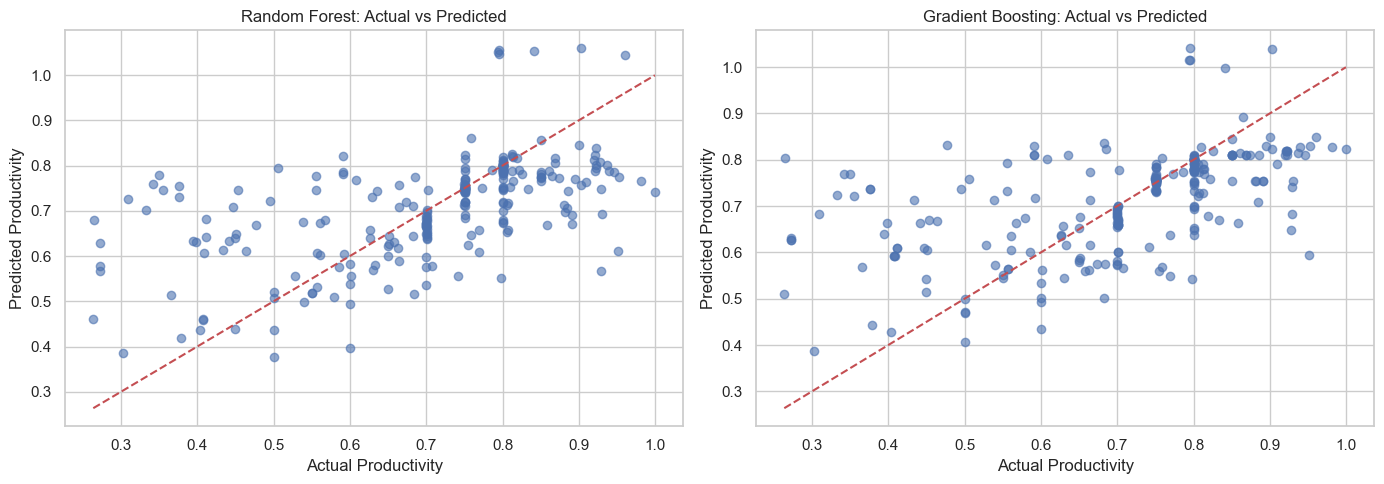

In [28]:
plt.figure(figsize=(14, 5))

for i, model_name in enumerate(
    ["Random Forest", "Gradient Boosting"], 1
):

    plt.subplot(1, 2, i)

    y_pred = predictions[model_name]

    plt.scatter(y_test, y_pred, alpha=0.6)

    plt.plot(
        [y_test.min(), y_test.max()],
        [y_test.min(), y_test.max()],
        "r--"
    )

    plt.xlabel("Actual Productivity")
    plt.ylabel("Predicted Productivity")
    plt.title(f"{model_name}: Actual vs Predicted")

plt.tight_layout()
plt.show()

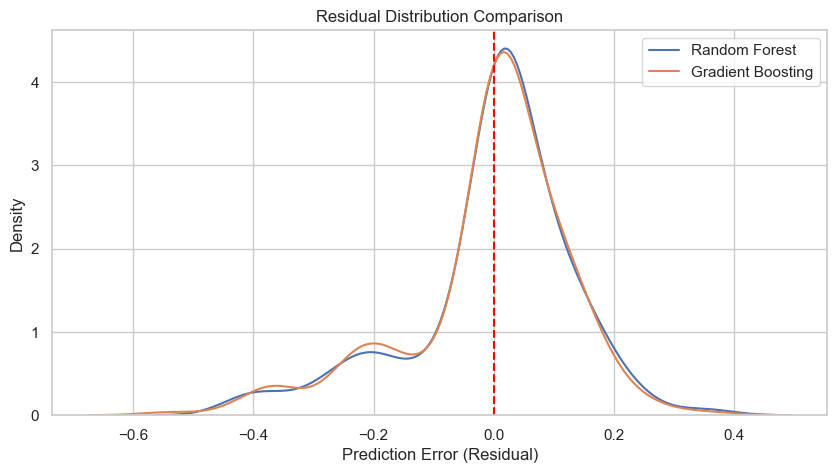

In [29]:
plt.figure(figsize=(10, 5))

for model_name in ["Random Forest", "Gradient Boosting"]:

    residuals = y_test.values - predictions[model_name]

    sns.kdeplot(
        residuals,
        label=model_name,
        fill=False
    )

plt.axvline(0, color="red", linestyle="--")

plt.xlabel("Prediction Error (Residual)")
plt.ylabel("Density")
plt.title("Residual Distribution Comparison")
plt.legend()
plt.show()

In [31]:
# Find the largest absolute transformed value
test_array = np.asarray(X_test_processed)

feature_names = preprocessor.get_feature_names_out()

max_position = np.unravel_index(
    np.abs(test_array).argmax(),
    test_array.shape
)

row_index, feature_index = max_position

print("Largest transformed value:",
      test_array[row_index, feature_index])

print("Feature:",
      feature_names[feature_index])

print("\nOriginal test record:")
display(X_test.iloc[row_index])

print("\nAll transformed feature values for this record:")
display(
    pd.DataFrame({
        "Feature": feature_names,
        "Value": test_array[row_index]
    }).sort_values(
        "Value",
        key=abs,
        ascending=False
    ).head(10)
)

Largest transformed value: 112.69003191877263
Feature: num__incentive

Original test record:


quarter                   Quarter2
department               finishing
day                         Monday
team                             9
targeted_productivity         0.75
smv                            2.9
over_time                        0
incentive                     3600
idle_time                      0.0
idle_men                         0
no_of_style_change               0
no_of_workers                 15.0
month                            3
day_of_month                     9
Name: 1133, dtype: object


All transformed feature values for this record:


,Feature,Value
3,num__incentive,112.690032
8,num__month,3.185331
2,num__over_time,-1.350105
1,num__smv,-1.120312
30,cat__team_9,1.000000
10,cat__quarter_Quarter2,1.000000
7,num__no_of_workers,-0.904279
9,num__day_of_month,-0.666766
6,num__no_of_style_change,-0.316424
0,num__targeted_productivity,0.173609


In [32]:
print("Training numerical feature ranges:")
display(X_train[numerical_features].describe().loc[["min", "max"]].T)

print("\nTesting numerical feature ranges:")
display(X_test[numerical_features].describe().loc[["min", "max"]].T)

Training numerical feature ranges:


,min,max
targeted_productivity,0.07,0.80
smv,2.90,54.56
over_time,0.00,25920.00
incentive,0.00,138.00
idle_time,0.00,300.00
idle_men,0.00,45.00
no_of_style_change,0.00,2.00
no_of_workers,2.00,89.00
month,1.00,2.00
day_of_month,1.00,31.00



Testing numerical feature ranges:


,min,max
targeted_productivity,0.35,0.80
smv,2.90,30.48
over_time,0.00,10500.00
incentive,0.00,3600.00
idle_time,0.00,6.50
idle_men,0.00,40.00
no_of_style_change,0.00,2.00
no_of_workers,6.00,59.00
month,2.00,3.00
day_of_month,1.00,28.00


In [35]:
# Load original dataset separately
df_original = pd.read_csv("../data/raw/garment_productivity.csv")

# Examine unusually high incentive values
high_incentives = df_original[
    df_original["incentive"] >= 960
][
    [
        "date",
        "department",
        "team",
        "incentive",
        "actual_productivity"
    ]
]

display(high_incentives)

print("Number of high-incentive records:", len(high_incentives))

print("\nIncentive distribution:")
display(df_original["incentive"].describe())

,date,department,team,incentive,actual_productivity
1128,3/9/2015,finishing,11,960,0.960625
1129,3/9/2015,finishing,12,1080,0.902963
1130,3/9/2015,finishing,5,2880,0.864343
1133,3/9/2015,finishing,9,3600,0.841000
1137,3/9/2015,finishing,3,1440,0.795417
1138,3/9/2015,finishing,4,960,0.795388
1139,3/9/2015,finishing,1,960,0.794567
1143,3/9/2015,finishing,2,1200,0.682500
1148,3/9/2015,finishing,10,960,0.477292
1149,3/9/2015,finishing,8,960,0.264062


Number of high-incentive records: 10

Incentive distribution:


count    1197.000000
mean       38.210526
std       160.182643
min         0.000000
25%         0.000000
50%         0.000000
75%        50.000000
max      3600.000000
Name: incentive, dtype: float64

In [37]:
# Define numerical features without incentive
numerical_features_no_incentive = [
    col for col in numerical_features
    if col != "incentive"
]

# Create a separate preprocessing pipeline
preprocessor_no_incentive = ColumnTransformer(
    transformers=[
        (
            "num",
            StandardScaler(),
            numerical_features_no_incentive
        ),
        (
            "cat",
            OneHotEncoder(
                drop="first",
                handle_unknown="ignore"
            ),
            categorical_features
        )
    ]
)

# Fit on training data and transform both datasets
X_train_no_incentive = preprocessor_no_incentive.fit_transform(
    X_train
)

X_test_no_incentive = preprocessor_no_incentive.transform(
    X_test
)

print("Training shape:", X_train_no_incentive.shape)
print("Testing shape:", X_test_no_incentive.shape)

Training shape: (943, 30)
Testing shape: (254, 30)


In [38]:
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

models_no_incentive = {
    "Linear Regression": LinearRegression(),
    "Ridge Regression": Ridge(alpha=1.0),
    "Random Forest": RandomForestRegressor(
        n_estimators=100,
        random_state=42
    ),
    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=100,
        random_state=42
    )
}

predictions_no_incentive = {}

for name, model in models_no_incentive.items():

    model.fit(X_train_no_incentive, y_train)

    y_pred = model.predict(X_test_no_incentive)

    predictions_no_incentive[name] = y_pred

    print(f"{name} trained and predicted successfully!")

/Users/sandali/Desktop/GitHub/manufacturing-demand-forecasting/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/Users/sandali/Desktop/GitHub/manufacturing-demand-forecasting/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.intercept_
/Users/sandali/Desktop/GitHub/manufacturing-demand-forecasting/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: invalid value encountered in matmul
  return X @ coef_ + self.intercept_
/Users/sandali/Desktop/GitHub/manufacturing-demand-forecasting/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/sandali/Desktop/GitHub/manufacturing-demand-forecasting/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: over

Linear Regression trained and predicted successfully!
Ridge Regression trained and predicted successfully!
Random Forest trained and predicted successfully!
Gradient Boosting trained and predicted successfully!


In [39]:
results_no_incentive = []

for name, y_pred in predictions_no_incentive.items():

    mae = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    r2 = r2_score(y_test, y_pred)

    results_no_incentive.append({
        "Model": name,
        "MAE": mae,
        "RMSE": rmse,
        "R2 Score": r2
    })

results_no_incentive_df = pd.DataFrame(
    results_no_incentive
).sort_values(by="RMSE")

display(results_no_incentive_df)

,Model,MAE,RMSE,R2 Score
1,Ridge Regression,0.096624,0.138877,0.263271
0,Linear Regression,0.096725,0.138908,0.262952
2,Random Forest,0.104337,0.142169,0.227931
3,Gradient Boosting,0.102689,0.145393,0.192524


In [40]:
# Extract Random Forest feature importance
rf_model = trained_models["Random Forest"]

feature_importance = pd.DataFrame({
    "Feature": preprocessor.get_feature_names_out(),
    "Importance": rf_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

display(feature_importance)

,Feature,Importance
0,num__targeted_productivity,0.230411
3,num__incentive,0.146052
1,num__smv,0.131715
9,num__day_of_month,0.100976
7,num__no_of_workers,0.074698
2,num__over_time,0.072164
16,cat__day_Sunday,0.019094
19,cat__day_Wednesday,0.017511
21,cat__team_11,0.016933
10,cat__quarter_Quarter2,0.014557


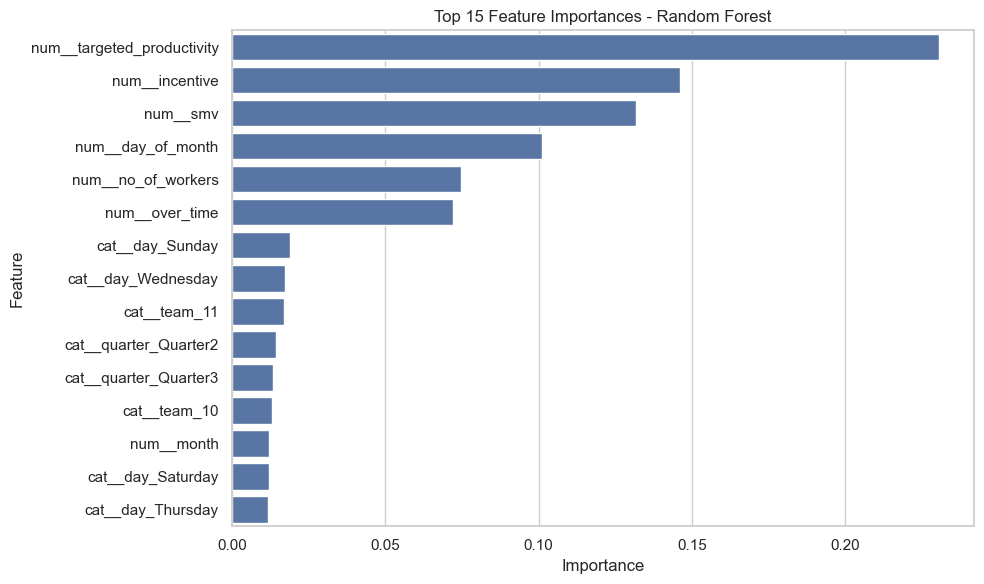

In [41]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=feature_importance.head(15),
    x="Importance",
    y="Feature"
)

plt.title("Top 15 Feature Importances - Random Forest")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

In [42]:
from sklearn.model_selection import RandomizedSearchCV, TimeSeriesSplit
from sklearn.ensemble import RandomForestRegressor

In [43]:
param_dist = {
    "n_estimators": [100, 200, 300, 500],
    "max_depth": [None, 5, 10, 15, 20],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4],
    "max_features": ["sqrt", 0.7, 1.0]
}

In [44]:
tscv = TimeSeriesSplit(n_splits=5)

rf = RandomForestRegressor(random_state=42)

random_search = RandomizedSearchCV(
    estimator=rf,
    param_distributions=param_dist,
    n_iter=30,
    cv=tscv,
    scoring="neg_root_mean_squared_error",
    random_state=42,
    n_jobs=-1,
    verbose=1
)

random_search.fit(X_train_processed, y_train)

Fitting 5 folds for each of 30 candidates, totalling 150 fits


RandomizedSearchCV(cv=TimeSeriesSplit(gap=0, max_train_size=None, n_splits=5, test_size=None),
                   estimator=RandomForestRegressor(random_state=42), n_iter=30,
                   n_jobs=-1,
                   param_distributions={'max_depth': [None, 5, 10, 15, 20],
                                        'max_features': ['sqrt', 0.7, 1.0],
                                        'min_samples_leaf': [1, 2, 4],
                                        'min_samples_split': [2, 5, 10],
                                        'n_estimators': [100, 200, 300, 500]},
                   random_state=42, scoring='neg_root_mean_squared_error',
                   verbose=1)

In [45]:
print("Best Parameters:")
print(random_search.best_params_)

print("\nBest Cross-validation RMSE:")
print(-random_search.best_score_)

Best Parameters:
{'n_estimators': 500, 'min_samples_split': 5, 'min_samples_leaf': 2, 'max_features': 0.7, 'max_depth': None}

Best Cross-validation RMSE:
0.14576087794371068


In [46]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Get the best tuned model
best_rf_model = random_search.best_estimator_

# Predict using the untouched test set
y_pred_tuned = best_rf_model.predict(X_test_processed)

# Evaluate
tuned_mae = mean_absolute_error(y_test, y_pred_tuned)
tuned_rmse = np.sqrt(mean_squared_error(y_test, y_pred_tuned))
tuned_r2 = r2_score(y_test, y_pred_tuned)

print("Tuned Random Forest Results")
print("---------------------------")
print("MAE:", tuned_mae)
print("RMSE:", tuned_rmse)
print("R2 Score:", tuned_r2)

Tuned Random Forest Results
---------------------------
MAE: 0.08941425967947043
RMSE: 0.13299047303947342
R2 Score: 0.32440709457705263


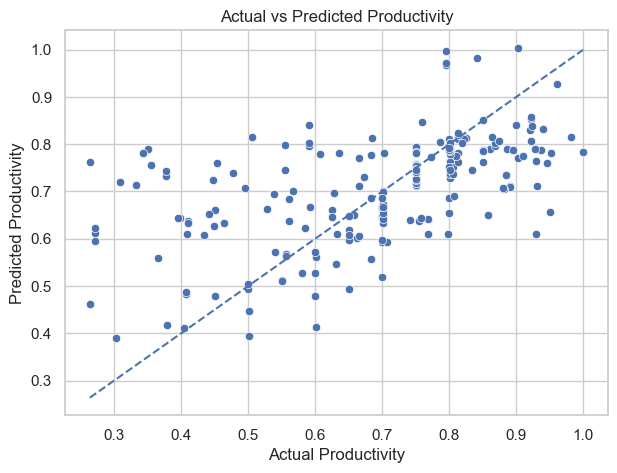

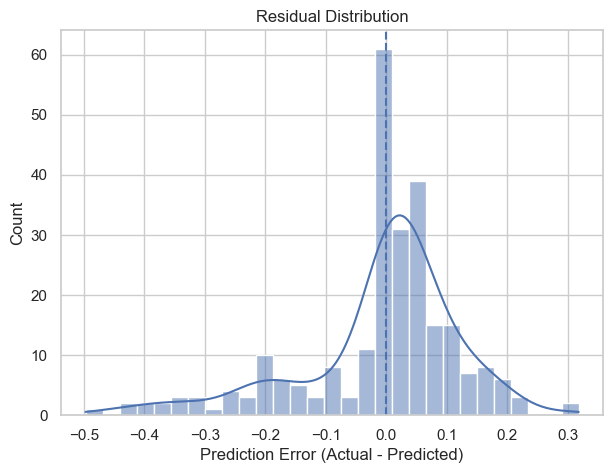

In [47]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Get predictions from the tuned model
best_rf_model = random_search.best_estimator_
y_pred_tuned = best_rf_model.predict(X_test_processed)

# Calculate residuals
residuals = y_test - y_pred_tuned

# Actual vs predicted
plt.figure(figsize=(7, 5))
sns.scatterplot(x=y_test, y=y_pred_tuned)
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle="--"
)
plt.xlabel("Actual Productivity")
plt.ylabel("Predicted Productivity")
plt.title("Actual vs Predicted Productivity")
plt.show()

# Residual distribution
plt.figure(figsize=(7, 5))
sns.histplot(residuals, kde=True)
plt.axvline(0, linestyle="--")
plt.xlabel("Prediction Error (Actual - Predicted)")
plt.title("Residual Distribution")
plt.show()